# Улучшение модели прогнозирования стоимости недвижимости

Мы прогнозируем стоимость недвижимости по характеристикам объектов. Цель проекта — улучшить исходную модель CatBoostRegressor: исследовать данные, создать и отобрать признаки, затем подобрать гиперпараметры. В Stage 2 исследуем качество данных, распределения, зависимости цены и гипотезы для дальнейших этапов. Исторический test оставляем для итоговой оценки.

## Конфигурация

Укажите абсолютный путь к историческому train.csv. Файл читается из внешнего каталога без копирования в репозиторий. Автоматической загрузки из интернета нет.

In [1]:
from pathlib import Path

TRAIN_PATH = Path("C:/Users/egpoz/mle-baseline-recovery/data/train.csv")

## Stage 2 — Исследовательский анализ данных (EDA)

Загрузим обучающую выборку и проверим размерность, типы столбцов, пропуски и полные дубликаты. Данные на этом этапе не изменяем.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
plt.rcParams.update({"figure.dpi": 90, "font.size": 9, "axes.titlesize": 10, "legend.fontsize": 8})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}".replace(",", " "))

In [3]:
if not TRAIN_PATH.is_absolute():
    raise ValueError("Укажите абсолютный путь в переменной TRAIN_PATH.")
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(f"Исторический train.csv не найден: {TRAIN_PATH}. Проверьте TRAIN_PATH и наличие локального файла.")

train = pd.read_csv(TRAIN_PATH)
print(f"Размерность: {train.shape[0]} строк, {train.shape[1]} столбцов")

import hashlib
train_md5_before = hashlib.md5(TRAIN_PATH.read_bytes()).hexdigest()
assert train_md5_before == "2d4bb3ba2091eb269bc56a93f05f9119", "Контрольная сумма train отличается от historical"
train_original = train.copy(deep=True)
assert train.price.gt(0).all(), "Для логарифмического цвета ожидается положительная цена"

Размерность: 112734 строк, 15 столбцов


In [4]:
print("Названия и типы столбцов:")
print(train.dtypes.to_string())

Названия и типы столбцов:
floor                  int64
kitchen_area         float64
living_area          float64
rooms                  int64
is_apartment            bool
total_area           float64
price                  int64
build_year             int64
building_type_int      int64
latitude             float64
longitude            float64
ceiling_height       float64
flats_count            int64
floors_total           int64
has_elevator            bool


In [5]:
print("Количество пропусков по столбцам:")
print(train.isna().sum().to_string())

Количество пропусков по столбцам:
floor                0
kitchen_area         0
living_area          0
rooms                0
is_apartment         0
total_area           0
price                0
build_year           0
building_type_int    0
latitude             0
longitude            0
ceiling_height       0
flats_count          0
floors_total         0
has_elevator         0


In [6]:
print(f"Количество полных дубликатов сверх первого вхождения: {train.duplicated().sum()}")

Количество полных дубликатов сверх первого вхождения: 5858


### Дубликаты и ограничения разбиения данных

Дубликаты считаем сверх первого вхождения. Проверяем все 15 столбцов и 14 признаков без целевой переменной `price`.

In [7]:
feature_columns = [c for c in train.columns if c != "price"]
assert len(train.columns) == 15 and len(feature_columns) == 14
price_counts = train.groupby(feature_columns, dropna=False)["price"].nunique()
duplicate_summary = pd.DataFrame({
    "Показатель": ["Полные дубликаты по 15 столбцам сверх первого вхождения", "Дубликаты по 14 признакам сверх первого вхождения", "Уникальные наборы из 14 признаков", "Группы одинаковых признаков с разными значениями price"],
    "Количество": [int(train.duplicated().sum()), int(train.duplicated(subset=feature_columns).sum()), int(train[feature_columns].drop_duplicates().shape[0]), int((price_counts > 1).sum())]
})
display(duplicate_summary)

,Показатель,Количество
0,Полные дубликаты по 15 столбцам сверх первого вхождения,5858
1,Дубликаты по 14 признакам сверх первого вхождения,12895
2,Уникальные наборы из 14 признаков,99839
3,Группы одинаковых признаков с разными значениями price,6526


Наличие дубликатов не означает автоматически ошибку данных. Одинаковые характеристики могут соответствовать разным объектам недвижимости. Удаление таких записей без дополнительного анализа не выполняется. Исходные данные сохраняются.

**Примечание о разбиении train/test.** В отдельном диагностическом аудите ранее выявлено полное совпадение всех 15 столбцов у **2 930 строк test (10,396%)** хотя бы с одной строкой train. Совпадение по 14 признакам без `price` найдено у **6 299 строк test (22,350%)**. Это результаты ранее проведённого аудита; historical test в Stage 2 не загружается. Возможно оптимистичное смещение исторической оценки качества. Исходное разбиение сохраняется для сопоставимости с baseline.

### Анализ целевой переменной

Исследуем только уже загруженную обучающую выборку. Денежные статистики приведены в рублях. Стандартное отклонение рассчитано с ddof=1. Для долей хвоста используем строгое превышение порога. Преобразование log1p используется только для графика и не меняет price.

In [8]:
price = train["price"]
price_quantiles = price.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
price_statistics = pd.DataFrame({
    "Показатель": ["Минимум", "Максимум", "Среднее", "Медиана", "Стандартное отклонение (ddof=1)"]
                  + [f"Квантиль {q:.0%}" for q in price_quantiles.index]
                  + ["Коэффициент асимметрии", "Отношение среднего к медиане"],
    "Значение": [price.min(), price.max(), price.mean(), price.median(), price.std()]
                + price_quantiles.tolist() + [price.skew(), price.mean() / price.median()],
    "Единица": ["руб."] * 12 + ["безразмерная", "безразмерная"],
})
display(price_statistics)

above_95 = price > price_quantiles.loc[0.95]
above_99 = price > price_quantiles.loc[0.99]
squared_deviations = (price - price.mean()) ** 2
price_tail_statistics = pd.DataFrame({
    "Показатель": ["Доля объектов выше 95-го процентиля", "Доля объектов выше 99-го процентиля",
                   "Доля суммы квадратов отклонений от среднего выше 99-го процентиля"],
    "Процент": [above_95.mean() * 100, above_99.mean() * 100,
                squared_deviations[above_99].sum() / squared_deviations.sum() * 100],
})
display(price_tail_statistics)

,Показатель,Значение,Единица
0,Минимум,46 000.000,руб.
1,Максимум,911 574 016.000,руб.
2,Среднее,18 521 813.574,руб.
3,Медиана,11 850 000.000,руб.
4,Стандартное отклонение (ddof=1),30 327 056.546,руб.
5,Квантиль 1%,5 300 000.000,руб.
6,Квантиль 5%,6 500 000.000,руб.
7,Квантиль 25%,8 929 287.500,руб.
8,Квантиль 50%,11 850 000.000,руб.
9,Квантиль 75%,16 900 000.000,руб.


,Показатель,Процент
0,Доля объектов выше 95-го процентиля,4.995
1,Доля объектов выше 99-го процентиля,1.001
2,Доля суммы квадратов отклонений от среднего выше 99-го процентиля,73.811


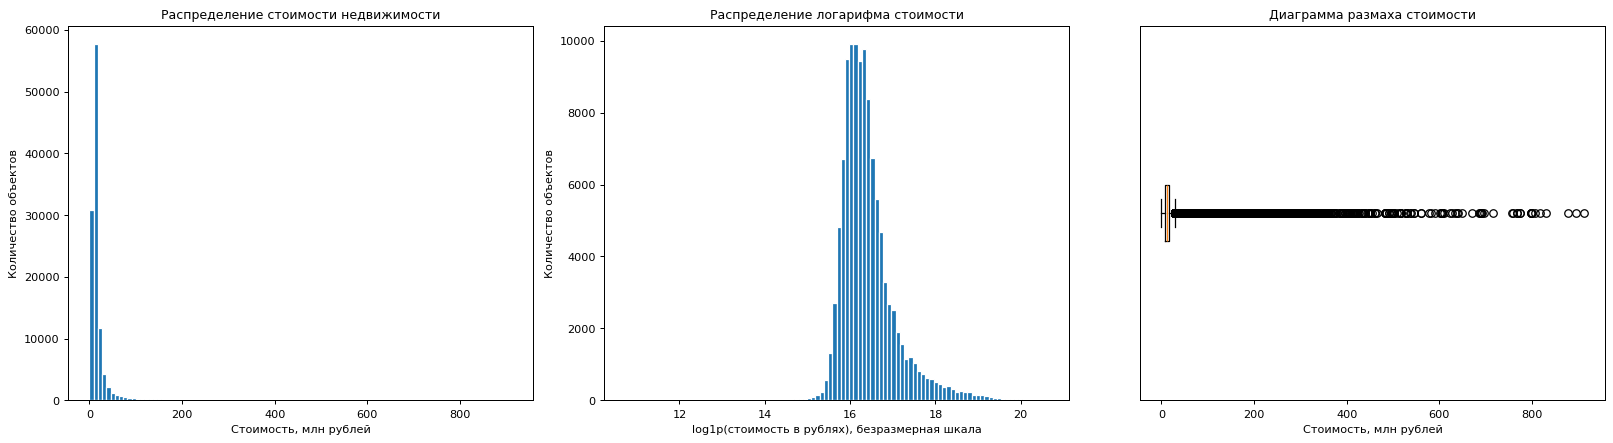

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(price / 1_000_000, bins=100, edgecolor="white")
axes[0].set(title="Распределение стоимости недвижимости", xlabel="Стоимость, млн рублей", ylabel="Количество объектов")
axes[1].hist(np.log1p(price), bins=100, edgecolor="white")
axes[1].set(title="Распределение логарифма стоимости", xlabel="log1p(стоимость в рублях), безразмерная шкала", ylabel="Количество объектов")
axes[2].boxplot(price / 1_000_000, vert=False)
axes[2].set(title="Диаграмма размаха стоимости", xlabel="Стоимость, млн рублей")
axes[2].set_yticks([])
fig.tight_layout()
plt.show()
plt.close(fig)

Распределение цены имеет выраженную правостороннюю асимметрию: коэффициент асимметрии равен **10,17**, среднее — **18,52 млн рублей**, медиана — **11,85 млн рублей**. Среднее превышает медиану в **1,56 раза**.

Правый хвост длинный: 95-й процентиль равен **48,50 млн рублей**, 99-й — **146,11 млн рублей**, а максимум достигает **911,57 млн рублей**. Выше этих порогов находятся соответственно **4,995%** и **1,001%** объектов. Из-за строгого сравнения и повторяющихся цен доли могут немного отличаться от 5% и 1%.

На объекты выше 99-го процентиля приходится **73,81%** общей суммы квадратов отклонений цены от среднего. Это показывает сильное влияние экстремальных цен на разброс target; показатель не является оценкой ошибок модели.

С учётом асимметрии и длинного хвоста целесообразно позже экспериментально проверить логарифмирование target. Улучшение качества пока не установлено: его нужно проверять отдельно с обратным преобразованием предсказаний и оценкой метрик в рублях. Сейчас target, исходные данные и функция потерь не изменяются; выбросы не удаляются.

### Числовые признаки и возможные аномалии

Все расчёты ниже используют только train. Основной DataFrame не изменяется. Крайние значения и нарушения соотношений служат поводом для проверки, а не автоматического удаления. В таблицах денежные показатели представлены в млн рублей. Для графиков используем плотность, групповые агрегаты и воспроизводимую выборку; численные выводы рассчитываем на всей выборке.

,count,mean,std,min,1%,25%,50%,75%,99%,max
total_area,112 734.000,62.177,39.560,11.000,29.100,39.200,53.000,72.000,222.000,960.300
living_area,112 734.000,37.116,25.461,2.000,14.000,20.890,31.000,44.000,140.000,608.641
kitchen_area,112 734.000,9.974,4.953,0.100,5.000,7.000,9.000,11.000,30.000,203.000
rooms,112 734.000,2.126,0.990,1.000,1.000,1.000,2.000,3.000,5.000,17.000
floor,112 734.000,7.471,5.735,1.000,1.000,3.000,6.000,10.000,25.000,56.000
floors_total,112 734.000,14.112,6.907,1.000,4.000,9.000,14.000,17.000,40.000,99.000
build_year,112 734.000,1 986.590,22.120,1 901.000,1 926.000,1 969.000,1 985.000,2 007.000,2 019.000,2 023.000
ceiling_height,112 734.000,2.753,0.214,2.000,2.480,2.640,2.640,2.800,3.400,8.000
flats_count,112 734.000,251.847,206.588,1.000,20.000,111.000,200.000,324.000,1 056.000,4 455.000


,Количество
Неположительная общая площадь,0
Неположительная этажность,0
Этаж вне диапазона 1…этажность,0
Неположительные жилая площадь или кухня,0
Жилая площадь или кухня больше общей,0
Сумма жилой площади и кухни больше общей,4
"Неположительные комнаты, высота, год или число квартир",0


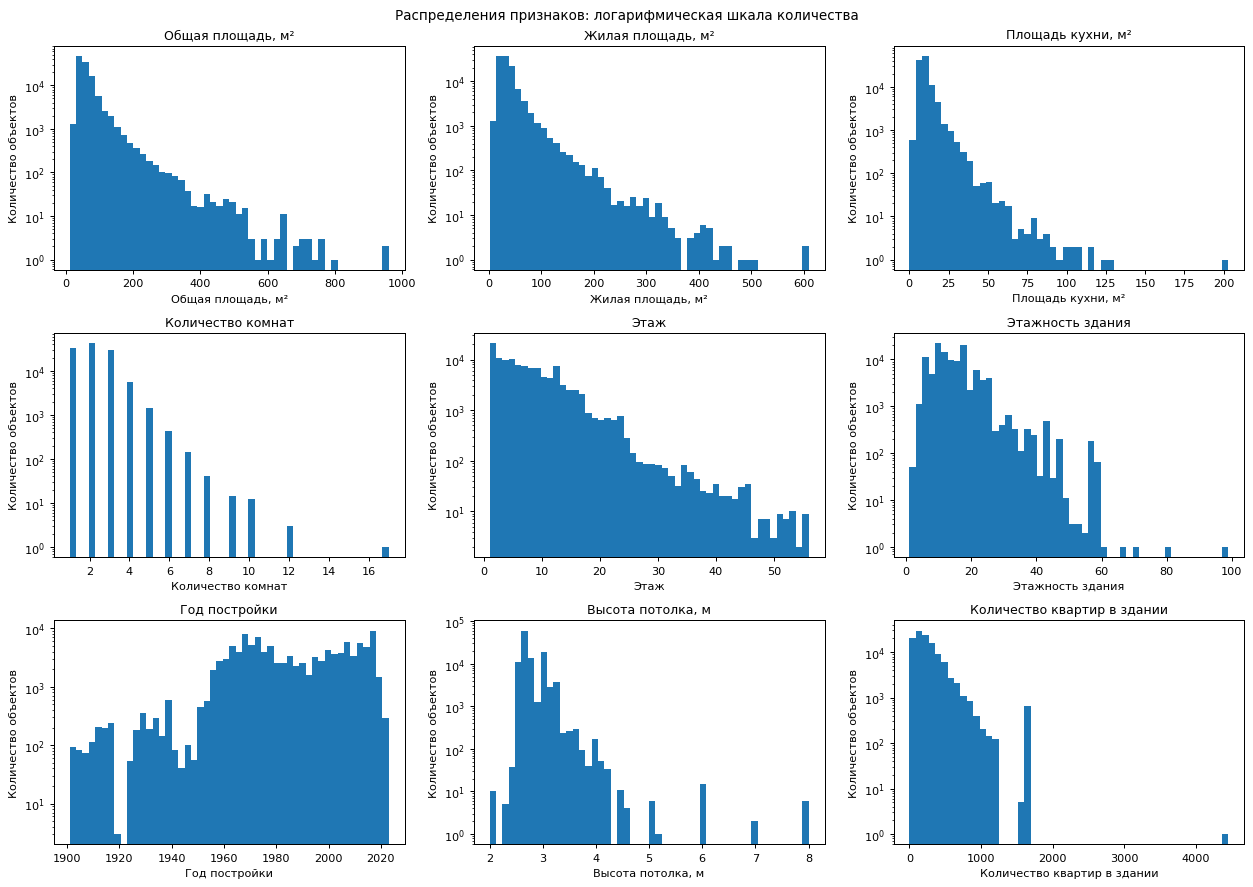

In [10]:
numeric_features = ["total_area", "living_area", "kitchen_area", "rooms", "floor", "floors_total", "build_year", "ceiling_height", "flats_count"]
labels = {"total_area": "Общая площадь, м²", "living_area": "Жилая площадь, м²", "kitchen_area": "Площадь кухни, м²", "rooms": "Количество комнат", "floor": "Этаж", "floors_total": "Этажность здания", "build_year": "Год постройки", "ceiling_height": "Высота потолка, м", "flats_count": "Количество квартир в здании"}
display(train[numeric_features].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))
anomalies = pd.Series({
    "Неположительная общая площадь": train.total_area.le(0).sum(),
    "Неположительная этажность": train.floors_total.le(0).sum(),
    "Этаж вне диапазона 1…этажность": (train.floor.lt(1) | train.floor.gt(train.floors_total)).sum(),
    "Неположительные жилая площадь или кухня": (train.living_area.le(0) | train.kitchen_area.le(0)).sum(),
    "Жилая площадь или кухня больше общей": (train.living_area.gt(train.total_area) | train.kitchen_area.gt(train.total_area)).sum(),
    "Сумма жилой площади и кухни больше общей": (train.living_area + train.kitchen_area > train.total_area).sum(),
    "Неположительные комнаты, высота, год или число квартир": train[["rooms", "ceiling_height", "build_year", "flats_count"]].le(0).any(axis=1).sum(),
}, name="Количество")
display(anomalies.to_frame())
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, numeric_features):
    ax.hist(train[col], bins=50)
    ax.set(xlabel=labels[col], ylabel="Количество объектов", title=labels[col])
    ax.set_yscale("log")
fig.suptitle("Распределения признаков: логарифмическая шкала количества")
fig.tight_layout(); plt.show(); plt.close(fig)

Диапазоны широкие: общая площадь 11–960,30 м², комнаты 1–17, этажность 1–99, потолки 2–8 м, число квартир 1–4 455. Это потенциально редкие объекты или ошибки, но сами диапазоны не устанавливают ошибочность. Найдены 4 нарушения суммы площадей; этажи согласованы с этажностью. Положительность и внутренние ограничения не подтверждают достоверность всех значений.

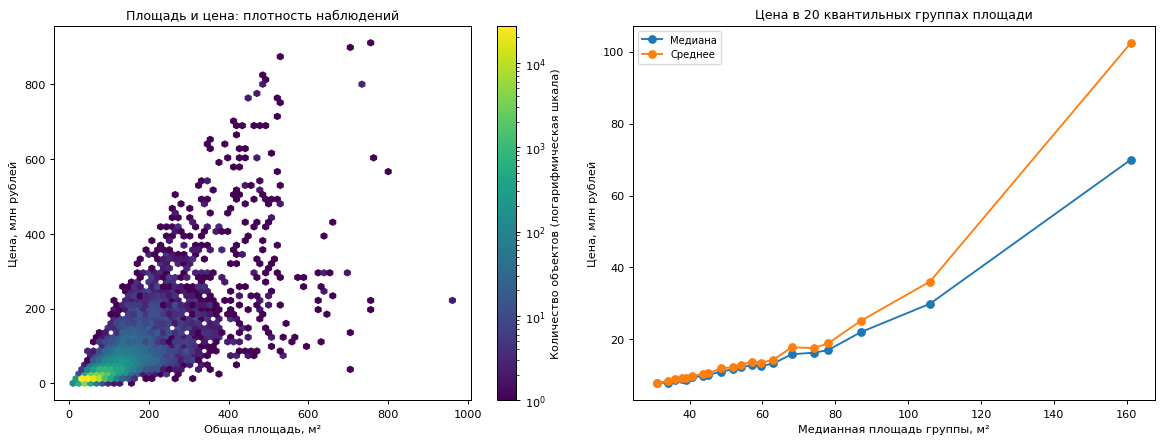

,Количество,"Медиана, млн ₽","Среднее, млн ₽"
rooms,,,
1,33588,8.550,9.265
2,42074,11.790,13.737
3,29368,16.000,21.938
4,5636,32.243,50.591
5,1419,70.000,103.006
6,435,130.000,168.367
7,143,140.000,209.113
8,41,224.075,324.583
9,14,236.690,248.702


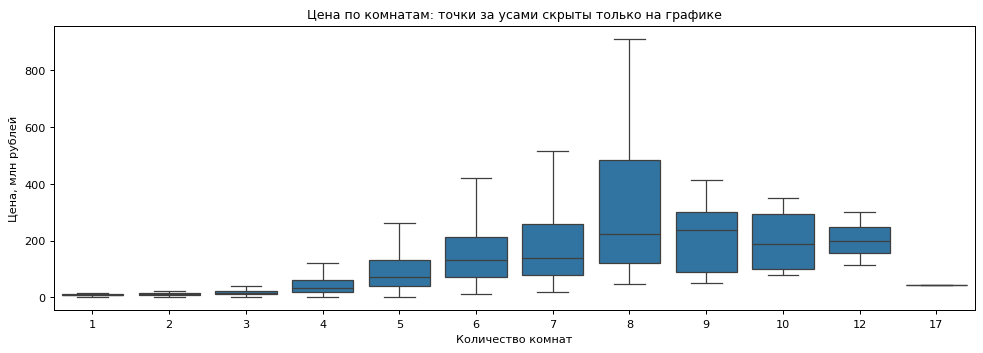

In [11]:
area_bins = pd.qcut(train.total_area, 20, duplicates="drop")
area_summary = train.groupby(area_bins, observed=True).agg(n=("price", "size"), area=("total_area", "median"), median=("price", "median"), mean=("price", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
h = axes[0].hexbin(train.total_area, train.price / 1e6, gridsize=65, bins="log", mincnt=1)
fig.colorbar(h, ax=axes[0], label="Количество объектов (логарифмическая шкала)")
axes[0].set(xlabel="Общая площадь, м²", ylabel="Цена, млн рублей", title="Площадь и цена: плотность наблюдений")
axes[1].plot(area_summary.area, area_summary["median"] / 1e6, marker="o", label="Медиана")
axes[1].plot(area_summary.area, area_summary["mean"] / 1e6, marker="o", label="Среднее")
axes[1].set(xlabel="Медианная площадь группы, м²", ylabel="Цена, млн рублей", title="Цена в 20 квантильных группах площади")
axes[1].legend(); fig.tight_layout(); plt.show(); plt.close(fig)
room_summary = train.groupby("rooms").price.agg(["size", "median", "mean"])
display(room_summary.assign(median=room_summary["median"] / 1e6, mean=room_summary["mean"] / 1e6).rename(columns={"size":"Количество", "median":"Медиана, млн ₽", "mean":"Среднее, млн ₽"}))
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=train.assign(price_mln=train.price / 1e6), x="rooms", y="price_mln", showfliers=False, ax=ax)
ax.set(xlabel="Количество комнат", ylabel="Цена, млн рублей", title="Цена по комнатам: точки за усами скрыты только на графике")
fig.tight_layout(); plt.show(); plt.close(fig)

,Количество,"Медиана, млн ₽","Среднее, млн ₽"
build_year,,,
"(1899.999, 1917.0]",1005,48.900,62.860
"(1917.0, 1960.0]",9359,16.500,19.991
"(1960.0, 1990.0]",51762,10.150,11.161
"(1990.0, 2010.0]",29191,13.900,26.653
"(2010.0, 2023.0]",21417,13.800,22.508


,Количество,"Медиана, млн ₽","Среднее, млн ₽"
Первый,9166,9.900,13.269
Последний,10531,11.500,21.639
Промежуточный,93037,12.000,18.686


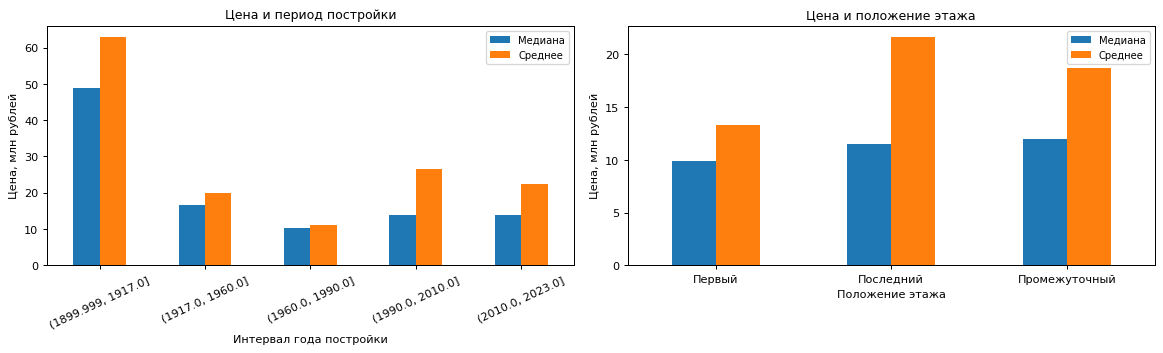

Одноэтажные объекты отнесены к первому этажу: 8


In [12]:
floor_group = pd.Series(np.select([train.floor.eq(1), train.floor.eq(train.floors_total)], ["Первый", "Последний"], default="Промежуточный"), index=train.index)
year_group = pd.cut(train.build_year, [1900, 1917, 1960, 1990, 2010, 2023], include_lowest=True)
year_summary = train.groupby(year_group, observed=True).price.agg(["size", "median", "mean"])
floor_summary = train.groupby(floor_group).price.agg(["size", "median", "mean"])
for summary in [year_summary, floor_summary]:
    display(summary.assign(median=summary["median"] / 1e6, mean=summary["mean"] / 1e6).rename(columns={"size":"Количество", "median":"Медиана, млн ₽", "mean":"Среднее, млн ₽"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
( year_summary[["median", "mean"]] / 1e6).rename(columns={"median":"Медиана", "mean":"Среднее"}).plot.bar(ax=axes[0], rot=25)
axes[0].set(xlabel="Интервал года постройки", ylabel="Цена, млн рублей", title="Цена и период постройки")
(floor_summary[["median", "mean"]] / 1e6).rename(columns={"median":"Медиана", "mean":"Среднее"}).plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel="Положение этажа", ylabel="Цена, млн рублей", title="Цена и положение этажа")
fig.tight_layout(); plt.show(); plt.close(fig)
print("Одноэтажные объекты отнесены к первому этажу:", int(train.floors_total.eq(1).sum()))

Связь цены с площадью положительная, но агрегаты и плотность нужны для оценки её формы и разброса: корреляция не доказывает линейность. Для комнат Spearman (0,650) выше Pearson (0,488), что согласуется с монотонной, но не обязательно линейной связью. Медианы по годам немонотонны: 48,90 млн рублей для 1901–1917 и 10,15 млн для 1961–1990. Это может отражать состав и местоположение объектов. Первый этаж имеет медиану 9,90 млн, промежуточный — 12,00 млн, последний — 11,50 млн рублей; без контроля площади и географии причинный эффект этажа не установлен.

Год постройки находится в диапазоне 1901–2023. Год наблюдения или продажи в train отсутствует; максимум года постройки не заменяет дату наблюдения. Поэтому возраст здания сейчас не вычисляем.

### Категориальные и бинарные признаки

Коды building_type_int рассматриваем как категории без предположений об их расшифровке и порядке. Сравниваем численности, средние, медианы и межквартильный разброс. Численность помогает оценить опору вывода, но не заменяет оценку неопределённости; повторы и общие здания могут снижать эффективный размер групп.

,Количество,"Среднее, млн ₽","Медиана, млн ₽","P25, млн ₽","P75, млн ₽","Доля, %"
building_type_int,,,,,,
0,1538,27.226,12.125,8.812,27.975,1.364
1,18457,22.311,14.500,10.000,23.159,16.372
2,20145,33.359,19.900,12.490,35.600,17.869
3,1371,105.407,43.000,18.000,150.000,1.216
4,62827,11.608,10.700,8.500,13.550,55.730
5,4,8.150,8.500,6.425,10.225,0.004
6,8392,10.546,9.700,8.100,12.000,7.444


,Количество,"Среднее, млн ₽","Медиана, млн ₽","P25, млн ₽","P75, млн ₽","Доля, %"
is_apartment,,,,,,
False,111660,18.497,11.800,8.900,16.850,99.047
True,1074,21.060,16.295,11.400,23.900,0.953


,Количество,"Среднее, млн ₽","Медиана, млн ₽","P25, млн ₽","P75, млн ₽","Доля, %"
has_elevator,,,,,,
False,11555,17.307,10.750,8.400,14.800,10.250
True,101179,18.661,11.999,9.000,17.000,89.750


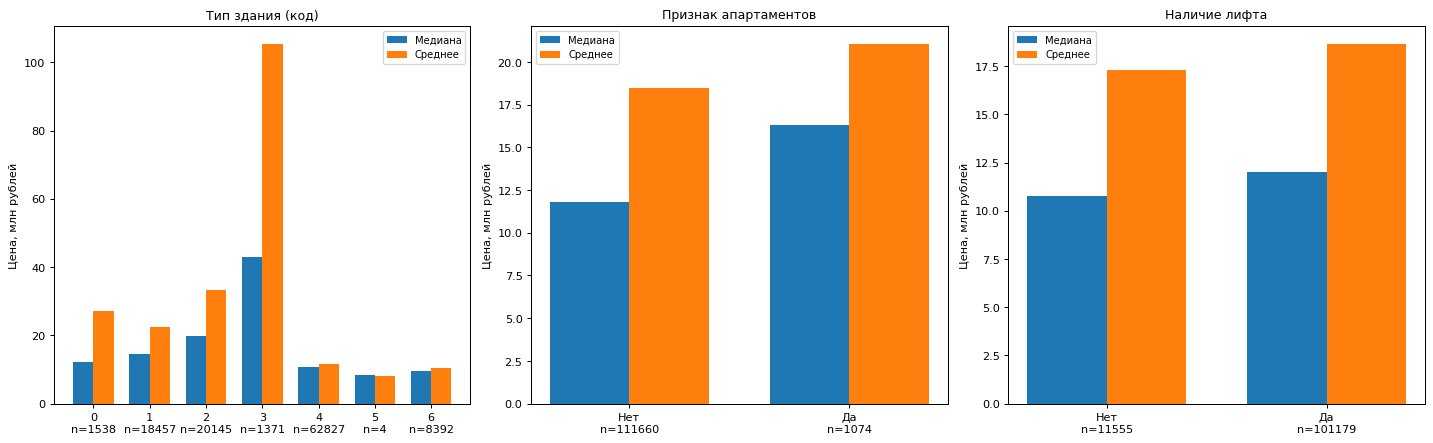

In [13]:
categorical_summary = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["building_type_int", "is_apartment", "has_elevator"]):
    s = train.groupby(col).price.agg(n="size", mean="mean", median="median", q25=lambda v: v.quantile(.25), q75=lambda v: v.quantile(.75))
    categorical_summary[col] = s
    report = s.copy(); report["Доля, %"] = report.n / len(train) * 100
    report[["mean", "median", "q25", "q75"]] /= 1e6
    display(report.rename(columns={"n":"Количество", "mean":"Среднее, млн ₽", "median":"Медиана, млн ₽", "q25":"P25, млн ₽", "q75":"P75, млн ₽"}).round(3))
    positions = np.arange(len(s))
    ax.bar(positions-.18, s["median"] / 1e6, width=.36, label="Медиана")
    ax.bar(positions+.18, s["mean"] / 1e6, width=.36, label="Среднее")
    ax.set_xticks(positions, [f"{({True: 'Да', False: 'Нет'}[v] if col != 'building_type_int' else v)}\nn={count}" for v, count in zip(s.index, s.n)])
    ax.set(title={"building_type_int":"Тип здания (код)", "is_apartment":"Признак апартаментов", "has_elevator":"Наличие лифта"}[col], ylabel="Цена, млн рублей")
    ax.legend()
fig.tight_layout(); plt.show(); plt.close(fig)

Для типа здания 5 есть только 4 наблюдения: его среднее и медиана нестабильны. Для типа 3 (1 371 объект) среднее 105,41 млн заметно выше медианы 43,00 млн рублей — хвост влияет и на групповые оценки. Апартаментов 1 074 против 111 660 остальных записей; медианы 16,295 и 11,80 млн рублей. С лифтом 101 179 объектов, без — 11 555; медианы 11,999 и 10,75 млн рублей. Различия описательные, а не причинные; даже крупные группы могут различаться по площади и географии.

### Географические закономерности

Используем только координаты из train, без внешних данных. Для scatter берём до 15 000 строк с random_state=42, для плотности и пространственных агрегатов — все строки. Границы ячеек сетки по 0,02 градуса — диагностическое предположение; градусы не являются расстоянием в километрах. Карта не задаёт административные границы.

,latitude,longitude
min,55.211,36.864
max,56.011,37.946
median,55.724,37.581


Координаты за физическими пределами: 0
Занятых ячеек сетки: 445 ; максимум объектов в ячейке: 1083
Доля объектов в 10 самых населённых ячейках, %: 7.400606737984991
Ячеек с n>=100: 309 ; диапазон медиан, млн рублей: {'min': 7.475, 'max': 146.91152}


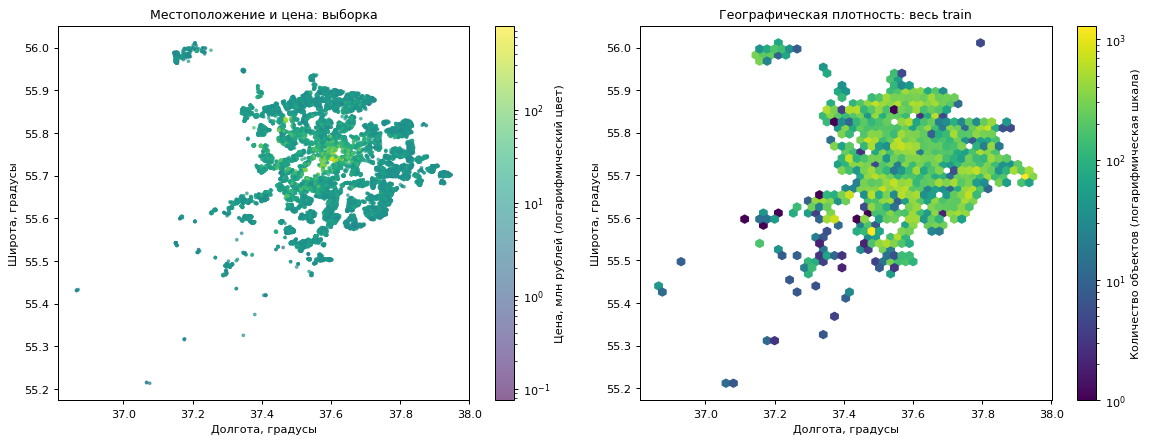

In [14]:
display(train[["latitude", "longitude"]].agg(["min", "max", "median"]))
print("Координаты за физическими пределами:", int((~train.latitude.between(-90,90) | ~train.longitude.between(-180,180)).sum()))
geo = train[["latitude", "longitude", "price"]].copy()
geo["lat_cell"] = np.floor(geo.latitude / .02).astype(int)
geo["lon_cell"] = np.floor(geo.longitude / .02).astype(int)
geo_groups = geo.groupby(["lat_cell", "lon_cell"]).price.agg(["size", "median"])
print("Занятых ячеек сетки:", len(geo_groups), "; максимум объектов в ячейке:", geo_groups["size"].max())
print("Доля объектов в 10 самых населённых ячейках, %:", geo_groups["size"].nlargest(10).sum() / len(train) * 100)
geo_supported = geo_groups[geo_groups["size"] >= 100]
print("Ячеек с n>=100:", len(geo_supported), "; диапазон медиан, млн рублей:", (geo_supported["median"] / 1e6).agg(["min", "max"]).to_dict())
from matplotlib.colors import LogNorm
sample = geo.sample(n=min(15000, len(geo)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter = axes[0].scatter(sample.longitude, sample.latitude, c=sample.price / 1e6, norm=LogNorm(), s=4, alpha=.6)
fig.colorbar(scatter, ax=axes[0], label="Цена, млн рублей (логарифмический цвет)")
h = axes[1].hexbin(geo.longitude, geo.latitude, gridsize=50, bins="log", mincnt=1)
fig.colorbar(h, ax=axes[1], label="Количество объектов (логарифмическая шкала)")
for ax, title in zip(axes, ["Местоположение и цена: выборка", "Географическая плотность: весь train"]):
    ax.set(xlabel="Долгота, градусы", ylabel="Широта, градусы", title=title)
fig.tight_layout(); plt.show(); plt.close(fig)

### Корреляционный анализ

Pearson описывает линейную связь и чувствителен к экстремальным значениям; Spearman — ранговую монотонную связь. Коды типа здания и бинарные категории исключены. Географические координаты включены, но слабая одномерная корреляция не исключает пространственных взаимодействий. Корреляция не означает причинность.

,Pearson с ценой,Spearman с ценой
total_area,0.783,0.764
living_area,0.753,0.720
kitchen_area,0.533,0.509
rooms,0.488,0.650
floor,0.059,0.148
floors_total,0.054,0.196
build_year,0.107,0.183
ceiling_height,0.443,0.489
flats_count,-0.069,0.003
latitude,0.029,0.064


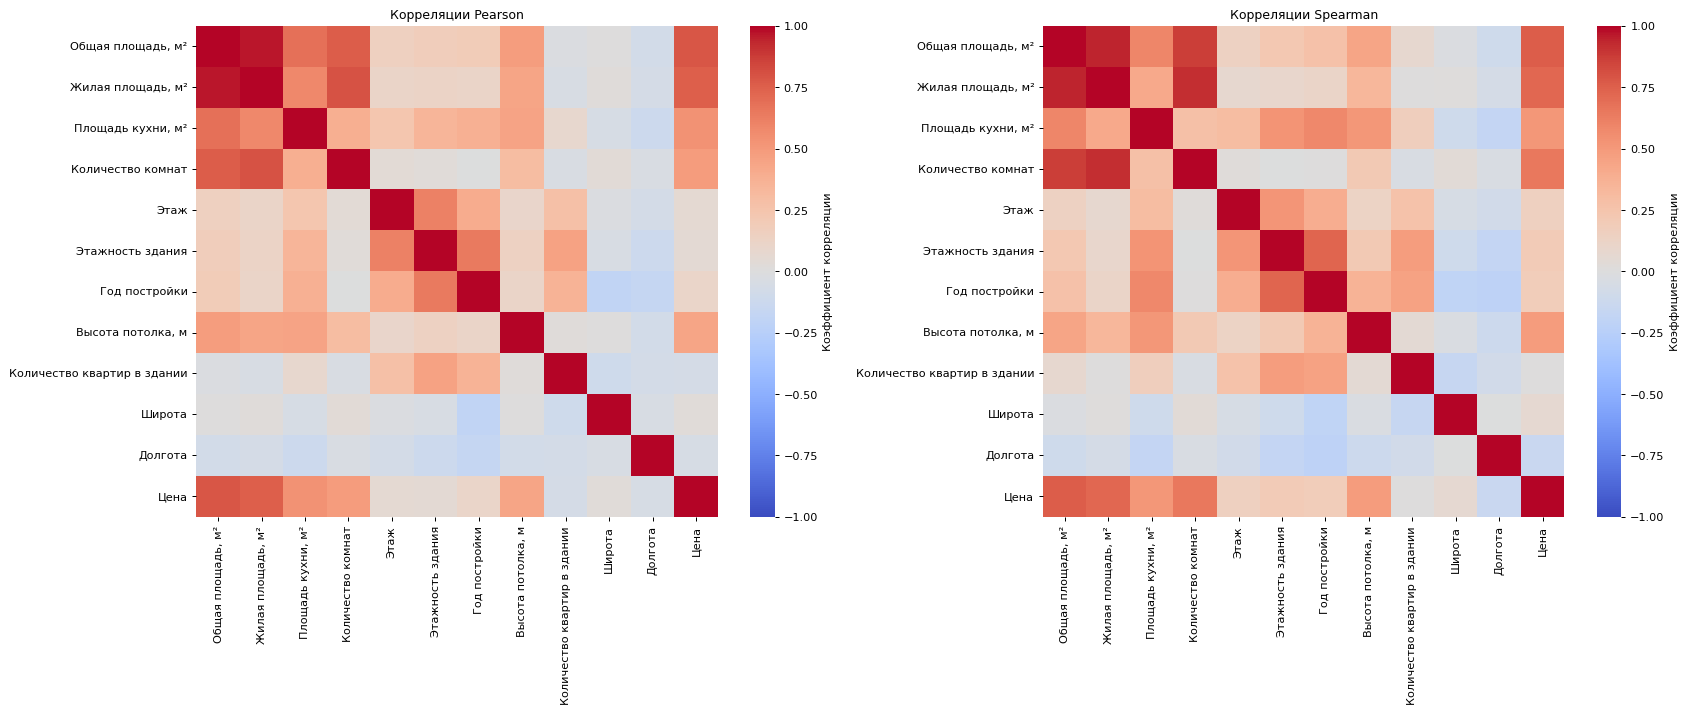

In [15]:
correlation_columns = numeric_features + ["latitude", "longitude", "price"]
pearson = train[correlation_columns].corr(method="pearson")
spearman = train[correlation_columns].corr(method="spearman")
display(pd.DataFrame({"Pearson с ценой":pearson.price, "Spearman с ценой":spearman.price}).drop(index="price").round(3))
correlation_labels = [labels.get(c, {"latitude":"Широта", "longitude":"Долгота", "price":"Цена"}.get(c,c)) for c in correlation_columns]
fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, matrix, title in zip(axes, [pearson,spearman], ["Корреляции Pearson", "Корреляции Spearman"]):
    sns.heatmap(matrix, vmin=-1, vmax=1, center=0, cmap="coolwarm", ax=ax, xticklabels=correlation_labels, yticklabels=correlation_labels, cbar_kws={"label":"Коэффициент корреляции"})
    ax.set_title(title)
fig.tight_layout(); plt.show(); plt.close(fig)

### Проверка гипотез о будущих признаках

Проверяем положительность знаменателей до вычисления отношений. Создаём только временную диагностическую таблицу. Не используем price_per_sqm и не включаем price в формулы будущих признаков. Групповые цены ниже — аналитические агрегаты target, они не становятся входами модели. Для взаимодействий считаем численности; пустые и малые группы не интерпретируем.

,count,mean,std,min,25%,50%,75%,max
Относительный этаж,112 734.000,0.538,0.290,0.025,0.286,0.529,0.786,1.000
Доля жилой площади,112 734.000,0.588,0.086,0.022,0.531,0.597,0.636,0.995
Доля кухни,112 734.000,0.175,0.060,0.005,0.132,0.166,0.212,0.798


,Spearman с ценой
Относительный этаж,0.043
Доля жилой площади,0.222
Доля кухни,-0.412


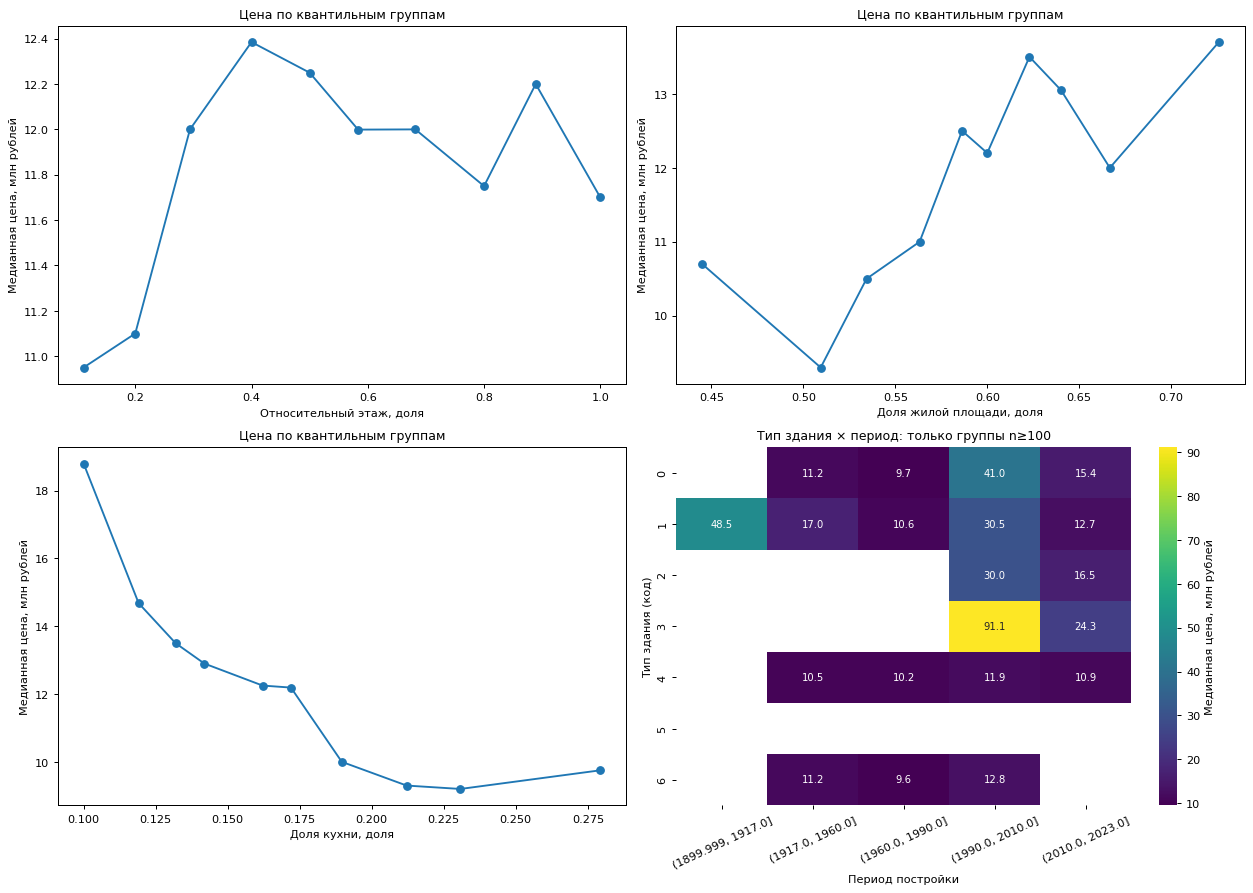

Диапазон медиан взаимодействий с n>=100, млн рублей: {'min': 9.55, 'max': 91.124544}


In [16]:
assert train.total_area.gt(0).all() and train.floors_total.gt(0).all()
diagnostic = pd.DataFrame({
    "Относительный этаж": train.floor / train.floors_total,
    "Доля жилой площади": train.living_area / train.total_area,
    "Доля кухни": train.kitchen_area / train.total_area,
    "price": train.price,
})
display(diagnostic.drop(columns="price").describe().T.round(3))
display(diagnostic.corr(method="spearman")[["price"]].drop(index="price").rename(columns={"price":"Spearman с ценой"}).round(3))
interaction = train.assign(period=year_group).groupby(["building_type_int", "period"], observed=True).price.agg(["size", "median"])
interaction_median = interaction["median"].where(interaction["size"] >= 100).unstack() / 1e6
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat[:3], diagnostic.columns[:3]):
    s = diagnostic.groupby(pd.qcut(diagnostic[col], 10, duplicates="drop"), observed=True).agg(x=(col,"median"), median=("price","median"), n=("price","size"))
    ax.plot(s.x, s["median"] / 1e6, marker="o")
    ax.set(xlabel=col+", доля", ylabel="Медианная цена, млн рублей", title="Цена по квантильным группам")
sns.heatmap(interaction_median, annot=True, fmt=".1f", ax=axes[1,1], annot_kws={"size": 8}, cmap="viridis", cbar_kws={"label":"Медианная цена, млн рублей"})
axes[1,1].set(title="Тип здания × период: только группы n≥100", xlabel="Период постройки", ylabel="Тип здания (код)")
axes[1,1].tick_params(axis="x", labelrotation=25)
fig.tight_layout(); plt.show(); plt.close(fig)
print("Диапазон медиан взаимодействий с n>=100, млн рублей:", interaction_median.stack().agg(["min","max"]).to_dict())

### Основные результаты EDA и гипотезы для Stage 3

1. **Target:** асимметрия 10,17, среднее/медиана 1,56; объекты строго выше P99 (1,001%) дают 73,81% суммы квадратов отклонений. Хвост сильно влияет на масштаб вариации; проверить логарифмирование target в отдельном эксперименте с оценкой в рублях, не меняя baseline сейчас.
2. **Дубликаты:** 5 858 полных повторов сверх первого вхождения и 6 526 групп одинаковых признаков с разными ценами. Характеристики могут не идентифицировать объект; ничего не удалять автоматически, учитывать зависимость наблюдений при проверке качества. Ранее выявленные пересечения test могут делать historical-оценку оптимистичной; исходный split сохраняется для сопоставимости.
3. **Площади:** Pearson общей площади с ценой 0,783, общей с жилой — 0,961. Размер объекта информативен, но площади частично избыточны; проверить доли площадей, не считать заранее доказанным их преимущество. Четыре нарушения суммы площадей требуют отдельного изучения источника.
4. **Комнаты:** Spearman с ценой 0,650 против Pearson 0,488. Наблюдается положительная ранговая связь; разница коэффициентов сама по себе не доказывает нелинейность; проверить взаимодействия комнат и площади. CatBoost уже умеет моделировать нелинейности, дополнительный признак может оказаться избыточным.
5. **Этажи и год:** медианы первого/промежуточного/последнего этажей 9,90/12,00/11,50 млн рублей, по периодам постройки — немонотонны. Возможны различия состава групп; проверить относительный этаж, оба индикатора и взаимодействия характеристик здания, не приписывая им причинный эффект. Возраст без года наблюдения не рассчитывать.
6. **Категории:** тип здания 5 имеет n=4, апартаменты n=1 074. Малые и неоднородные группы ограничивают устойчивость оценок; сохранять тип здания категориальным, избегать выводов по редким группам и кодирования средним target на всей выборке.
7. **География:** широта 55,21146–56,011032°, долгота 36,864372–37,946411°, физически невозможных координат нет. Одномерная Spearman-корреляция с ценой мала (0,064 и −0,146), но это не исключает локальных закономерностей; проверить взаимодействие координат и сеточные признаки. Выбор размера сетки остаётся гипотезой, а географическая достоверность без внешнего источника не подтверждена.

| Гипотеза | Основание из EDA | Возможное преобразование | Приоритет проверки |
|---|---|---|---|
| Стабилизация масштаба target | Асимметрия 10,17; вклад хвоста 73,81% | log1p(target) с обратным преобразованием | Высокий |
| Относительная планировка | Общая и жилая площади коррелируют на 0,961 | living_area/total_area, kitchen_area/total_area | Высокий |
| Положение в здании | Различаются медианы этажных групп | floor/floors_total; первый и последний этаж | Высокий |
| Пространственные взаимодействия | Координаты описывают локализацию; слабая одномерная связь не исключает совместную | Сетка координат, взаимодействия с площадью | Высокий |
| Нелинейный эффект здания | Немонотонные цены по периодам и различия типов | Период постройки × тип здания; потолок × площадь | Средний |
| Планировка при одинаковой площади | Ранговая связь комнат с ценой сильнее линейной | Площадь на комнату после проверки знаменателя | Средний |

Это кандидаты для контролируемых экспериментов, а не установленные улучшения качества. Графики и групповые сравнения не устраняют смешение по площади, местоположению и повторным объектам. Target-агрегаты не используются как признаки; Stage 3–5 не реализованы.

Дополнительные результаты проверки гипотез: Spearman относительного этажа с ценой **0,043**, доли жилой площади **0,222**, доли кухни **−0,412**. Это не доказывает дополнительную полезность поверх исходных площадей. В сетке 0,02° заняты **445** ячеек; на 10 самых населённых приходится **7,40%** записей. В **309** ячейках с n≥100 медиана цены находится между **7,475** и **146,912 млн рублей**. Различия могут объясняться как местоположением, так и составом объектов. Для взаимодействия типа здания и периода (группы n≥100) диапазон медиан **9,55–91,125 млн рублей**; это основание проверить взаимодействия, а не свидетельство причинности или улучшения модели.

### Самопроверка и воспроизводимость

Проверяем, что исходный train в памяти и контрольная сумма локального CSV не изменились. Проверки не используют test. Историческое пересечение из отдельного аудита не является основанием для подбора признаков на test.

In [17]:
pd.testing.assert_frame_equal(train, train_original)
assert hashlib.md5(TRAIN_PATH.read_bytes()).hexdigest() == train_md5_before
assert train.shape == (112734, 15)
assert int(train.isna().sum().sum()) == 0
assert int(train.duplicated().sum()) == 5858
assert np.isclose(price.skew(), 10.169112077639722)
assert np.isclose(squared_deviations[above_99].sum() / squared_deviations.sum() * 100, 73.81055131962627)
assert np.isclose(pearson.loc["total_area", "living_area"], 0.961281, atol=1e-6)
print("Самопроверка пройдена: train не изменён, историческая контрольная сумма и основные результаты совпадают.")

Самопроверка пройдена: train не изменён, историческая контрольная сумма и основные результаты совпадают.


### Логирование Stage 2 в MLflow

Логирование выполняется отдельно после сохранения notebook и отчёта командой из корня репозитория:

    .\.venv\Scripts\python.exe -B mlflow_server/log_stage2.py

Так в artifacts попадут сохранённые результаты, а обычный запуск EDA не создаст run. Experiment: real_estate_model_improvement; run name: stage2_eda. Скрипт использует существующую конфигурацию, проверяет health и соответствие PostgreSQL/Registry, не создаёт эксперимент и не меняет модель. При отсутствии сервера останавливается. Повторный запуск для того же снимка файлов переиспользует завершённый run.

Проверка 2026-10-28: локальный сервер отклонил подключение (10061); Stage 2 run пока не создан. Инфраструктура автоматически не запускается.

## Stage 3 — Генерация признаков

Этот этап будет реализован позже.

## Stage 4 — Отбор признаков

Этот этап будет реализован позже.

## Stage 5 — Подбор гиперпараметров

Этот этап будет реализован позже.